# 03 - Visualización

## Importar librerías

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Mejorar la visualización

In [2]:
# Que muestre todas las columnas
pd.options.display.max_columns = None
# En los dataframes, mostrar los float con dos decimales
pd.options.display.float_format = '{:,.2f}'.format

In [3]:
sns.set_style("whitegrid")

## Establecer las rutas

In [4]:
RAIZ = Path.cwd().resolve()
for carpeta in [RAIZ, *RAIZ.parents]:
    if (carpeta / 'requirements.txt').is_file() and (carpeta / 'data').is_dir():
        RAIZ = carpeta
        break
else:
    raise FileNotFoundError('Abra el notebook desde el proyecto.')

PROCESSED = RAIZ / 'data/processed'
REPORTS = RAIZ / 'data/reports/03_visualizacion'
REPORTS.mkdir(parents=True, exist_ok=True)

## Cargar la base

In [5]:
variables = ['gdp_real_usd', 'dist', 'contig', 'comlang_off', 'fta_in_force', 'wto_d', 'oecd_d']
base = pd.read_parquet(PROCESSED / 'baci/baci_exports_COL_2017_2024_HS2017_V202601.parquet',
    columns = ['year', 'partner_iso3', 'hs6', 'hs6_name', 'trade_value_usd'])
base.rename(columns = {'partner_iso3': 'iso3_d'}, inplace = True)
base = base.merge(pd.read_parquet(PROCESSED / 'variables/base_final_variables_COL_2017_2024.parquet',
    columns = ['iso3_d', 'nombre_destino', 'year', *variables]),
    on = ['iso3_d', 'year'], how = 'inner', validate = 'many_to_one')

## Explorar la base

In [6]:
base.head()

,year,iso3_d,hs6,hs6_name,trade_value_usd,nombre_destino,gdp_real_usd,dist,contig,comlang_off,fta_in_force,wto_d,oecd_d
0,2017,ALB,080390,"Fruit, edible: bananas, other than plantains, ...","1,676,907.00",Albania,"12,309,839,868.71","10,001.00",0,0,0,1,0
1,2017,ALB,090111,Coffee: not roasted or decaffeinated,"145,493.00",Albania,"12,309,839,868.71","10,001.00",0,0,0,1,0
2,2017,ALB,170114,"Sugars: cane sugar, raw, in solid form, other ...","15,523.00",Albania,"12,309,839,868.71","10,001.00",0,0,0,1,0
3,2017,ALB,250700,Kaolin and other kaolinic clays: whether or no...,"50,000.00",Albania,"12,309,839,868.71","10,001.00",0,0,0,1,0
4,2017,ALB,270400,"Coke and semi-coke: of coal, lignite or peat, ...","946,757.00",Albania,"12,309,839,868.71","10,001.00",0,0,0,1,0


In [7]:
base.shape

(412118, 13)

In [8]:
base.info()

<class 'pandas.DataFrame'>
RangeIndex: 412118 entries, 0 to 412117
Data columns (total 13 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   year             412118 non-null  int16  
 1   iso3_d           412118 non-null  object 
 2   hs6              412118 non-null  string 
 3   hs6_name         412118 non-null  str    
 4   trade_value_usd  412118 non-null  float64
 5   nombre_destino   412118 non-null  str    
 6   gdp_real_usd     412118 non-null  float64
 7   dist             412118 non-null  float64
 8   contig           412118 non-null  Int8   
 9   comlang_off      412118 non-null  Int8   
 10  fta_in_force     412118 non-null  Int8   
 11  wto_d            412118 non-null  Int8   
 12  oecd_d           412118 non-null  Int8   
dtypes: Int8(5), float64(3), int16(1), object(1), str(2), string(1)
memory usage: 73.7+ MB


In [9]:
base.nunique()

year                    8
iso3_d                197
hs6                  4930
hs6_name             4928
trade_value_usd    123426
nombre_destino        197
gdp_real_usd         1461
dist                  197
contig                  2
comlang_off             2
fta_in_force            2
wto_d                   2
oecd_d                  2
dtype: int64

In [10]:
base.duplicated(['hs6', 'iso3_d', 'year']).sum()

np.int64(0)

## Consultar los valores faltantes

In [11]:
base.isna().sum()

year               0
iso3_d             0
hs6                0
hs6_name           0
trade_value_usd    0
nombre_destino     0
gdp_real_usd       0
dist               0
contig             0
comlang_off        0
fta_in_force       0
wto_d              0
oecd_d             0
dtype: int64

## Consultar las estadísticas descriptivas

In [12]:
base.describe().T

,count,mean,std,min,25%,50%,75%,max
year,"412,118.00","2,020.63",2.29,"2,017.00","2,019.00","2,021.00","2,023.00","2,024.00"
trade_value_usd,"412,118.00","896,018.66","31,226,728.96",1.00,481.00,"4,303.00","37,533.75","6,088,627,349.00"
gdp_real_usd,"412,118.00","1,596,557,995,641.43","4,484,937,181,802.25","219,000,000.00","54,297,264,368.63","115,463,874,454.86","911,031,844,894.18","22,731,468,331,925.10"
dist,"412,118.00","5,487.25","4,783.05",772.00,"1,601.00","3,999.00","9,076.00","19,806.00"
contig,"412,118.00",0.17,0.38,0.00,0.00,0.00,0.00,1.00
comlang_off,"412,118.00",0.51,0.50,0.00,0.00,1.00,1.00,1.00
fta_in_force,"412,118.00",0.64,0.48,0.00,0.00,1.00,1.00,1.00
wto_d,"412,118.00",0.95,0.21,0.00,1.00,1.00,1.00,1.00
oecd_d,"412,118.00",0.38,0.49,0.00,0.00,0.00,1.00,1.00


## Consultar los años y los destinos

In [13]:
base['year'].value_counts().sort_index()

year
2017    47138
2018    48735
2019    50120
2020    49028
2021    52745
2022    53415
2023    55496
2024    55441
Name: count, dtype: int64

In [14]:
base['nombre_destino'].value_counts()

nombre_destino
Ecuador                              20276
Estados Unidos de América            18118
Panamá                               17546
Costa Rica                           16643
Perú                                 15464
                                     ...  
Vanuatu                                  3
Micronesia (Estados Federados de)        1
Islas Marianas Septentrionales           1
Samoa Americana                          1
Islas Marshall                           1
Name: count, Length: 197, dtype: int64

## Graficar la evolución comercial

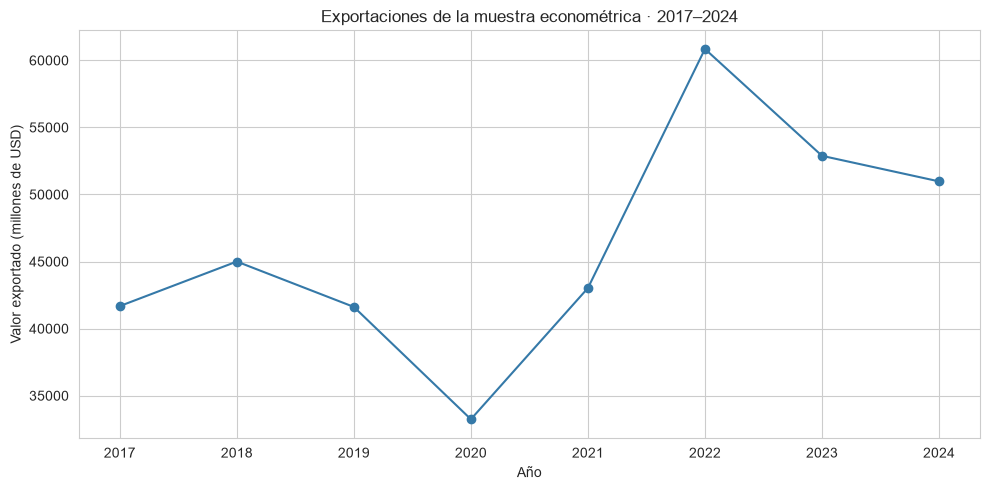

In [15]:
base.groupby('year')['trade_value_usd'].sum().div(1_000_000).plot(
    figsize = (10, 5), marker = 'o', color = '#3579a8')
plt.title('Exportaciones de la muestra econométrica · 2017–2024')
plt.xlabel('Año')
plt.ylabel('Valor exportado (millones de USD)')
plt.tight_layout()
plt.savefig(REPORTS / 'evolucion_comercial.png', dpi = 180)
plt.show()

## Resumir la diversificación por producto HS6

In [16]:
productos = base.loc[base['trade_value_usd'].gt(0)].groupby('hs6', as_index = False).agg(
    nombre_producto = ('hs6_name', 'first'), paises_destino = ('iso3_d', 'nunique'),
    valor_exportado_usd = ('trade_value_usd', 'sum'))
productos['valor_miles_millones_usd'] = productos['valor_exportado_usd'] / 1_000_000_000
productos.nlargest(10, 'valor_exportado_usd')

,hs6,nombre_producto,paises_destino,valor_exportado_usd,valor_miles_millones_usd
872,270900,Oils: petroleum oils and oils obtained from bi...,35,"100,426,019,701.00",100.43
854,270112,"Coal: bituminous, whether or not pulverised, b...",66,"52,441,039,638.00",52.44
378,090111,Coffee: not roasted or decaffeinated,126,"23,435,054,762.00",23.44
873,271000,Petroleum oils and oils from bituminous minera...,110,"19,626,591,749.00",19.63
3114,710812,"Metals: gold, non-monetary, unwrought (but not...",24,"17,504,525,073.00",17.50
855,270119,"Coal: (other than anthracite and bituminous), ...",57,"9,410,832,500.00",9.41
333,080390,"Fruit, edible: bananas, other than plantains, ...",87,"8,973,947,357.00",8.97
860,270400,"Coke and semi-coke: of coal, lignite or peat, ...",57,"8,486,691,647.00",8.49
3152,720260,Ferro-alloys: ferro-nickel,35,"4,602,278,358.00",4.60
243,060319,"Flowers, cut: flowers and buds of a kind suita...",115,"4,538,546,340.00",4.54


## Graficar el valor exportado y la diversificación

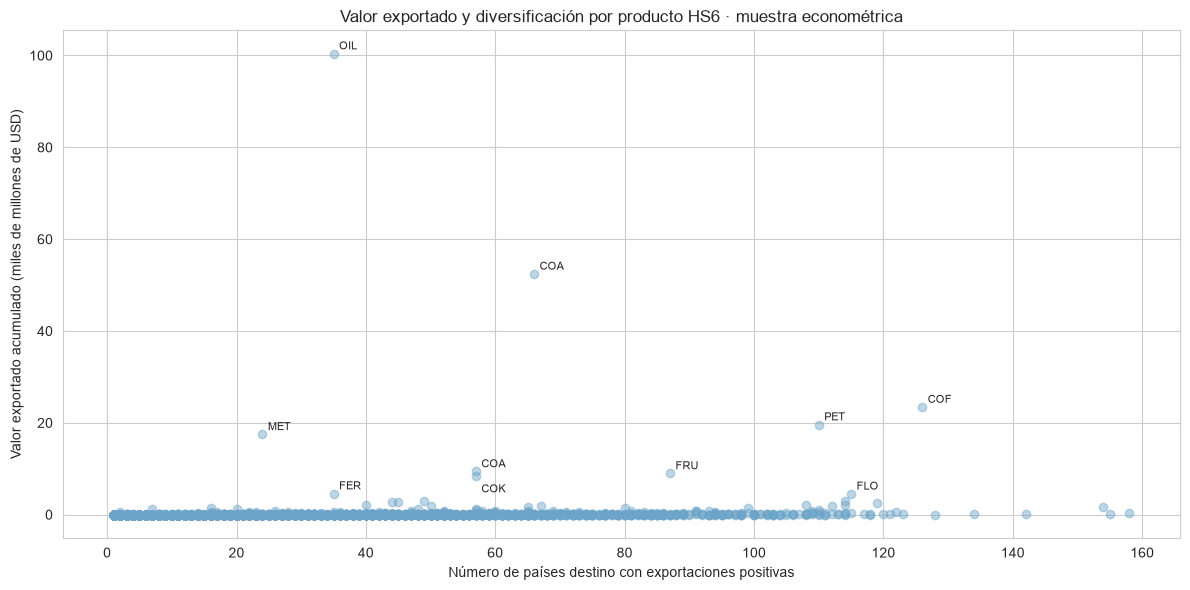

In [17]:
plt.figure(figsize = (12, 6))
plt.scatter(productos['paises_destino'], productos['valor_miles_millones_usd'], alpha = .45, color = '#6ba4c8')
for fila in productos.nlargest(10, 'valor_exportado_usd').itertuples(index = False):
    plt.annotate(fila.nombre_producto[:3].upper(), (fila.paises_destino, fila.valor_miles_millones_usd),
        xytext = (4, -12 if fila.hs6 == '270400' else 3), textcoords = 'offset points', fontsize = 8)
plt.title('Valor exportado y diversificación por producto HS6 · muestra econométrica')
plt.xlabel('Número de países destino con exportaciones positivas')
plt.ylabel('Valor exportado acumulado (miles de millones de USD)')
plt.tight_layout()
plt.savefig(REPORTS / 'diversificacion_hs6.png', dpi = 180)
plt.show()

## Calcular la matriz de correlación

In [18]:
correlacion = base[variables].corr()
correlacion

,gdp_real_usd,dist,contig,comlang_off,fta_in_force,wto_d,oecd_d
gdp_real_usd,1.00,0.09,-0.13,-0.31,0.14,0.08,0.32
dist,0.09,1.00,-0.39,-0.68,-0.16,0.11,0.29
contig,-0.13,-0.39,1.00,0.36,-0.04,0.10,-0.36
comlang_off,-0.31,-0.68,0.36,1.00,0.15,0.08,-0.36
fta_in_force,0.14,-0.16,-0.04,0.15,1.00,0.29,0.49
wto_d,0.08,0.11,0.10,0.08,0.29,1.00,0.18
oecd_d,0.32,0.29,-0.36,-0.36,0.49,0.18,1.00


## Graficar la matriz de correlación

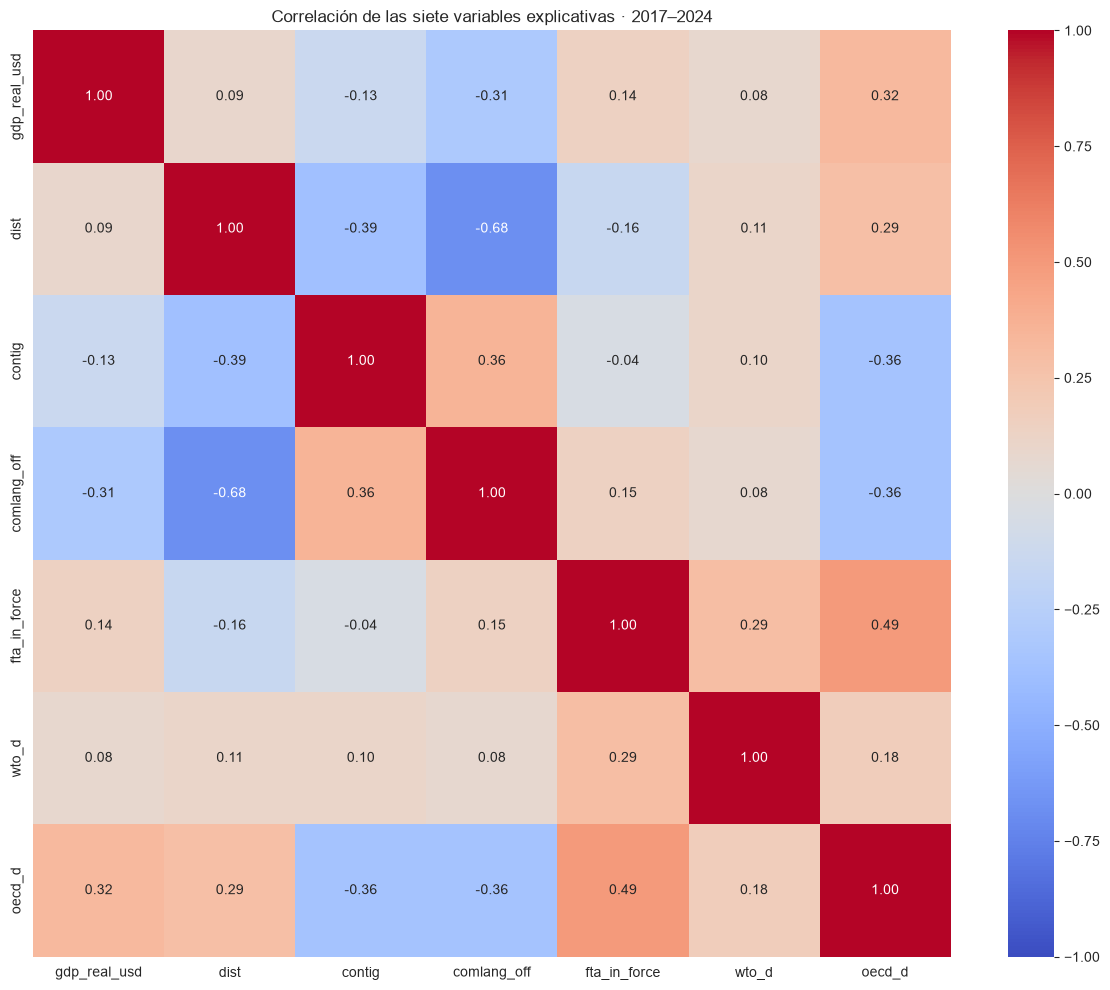

In [19]:
plt.figure(figsize = (12, 10))
sns.heatmap(correlacion, annot = True, cmap = 'coolwarm', fmt = '.2f', vmin = -1, vmax = 1)
plt.title('Correlación de las siete variables explicativas · 2017–2024')
plt.tight_layout()
plt.savefig(REPORTS / 'correlacion_base.png', dpi = 180)
plt.show()